# How well do jobs and skills pay for Data Analysts?

Methodology
1. Evaluate median salary for top 6 data jobs
2. Find median salary per skill for Data Analysts
3. Visualize for highest paying skills and most demanded skills

In [4]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading our data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\dorac\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [26]:
# Filter for the job titles and country of interest
df_RO = df[df['job_country'] == 'Romania'].dropna(subset=['salary_year_avg'])

In [27]:
job_titles = df_RO['job_title_short'].value_counts().index[:6].to_list()

job_titles

['Data Analyst',
 'Data Scientist',
 'Data Engineer',
 'Senior Data Analyst',
 'Software Engineer',
 'Machine Learning Engineer']

In [28]:
df_RO_top6 = df_RO[df_RO['job_title_short'].isin(job_titles)]

In [29]:
job_order = df_RO_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index

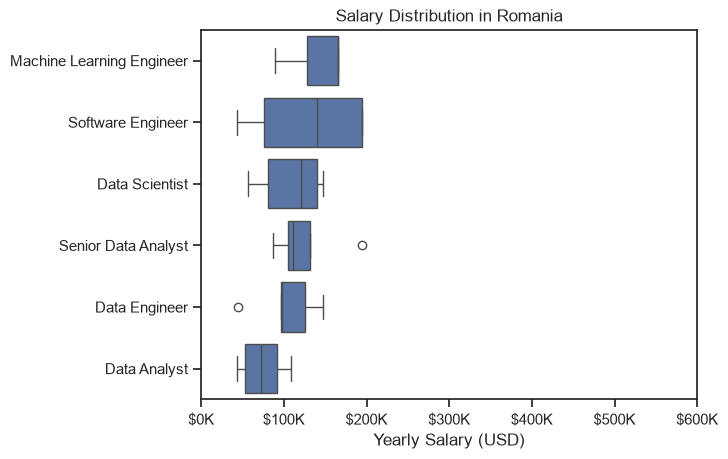

In [30]:
sns.boxplot(data=df_RO_top6, x='salary_year_avg', y='job_title_short', order = job_order)
sns.set_theme(style='ticks')

plt.title('Salary Distribution in Romania')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('')
plt.xlim(0, 600000)
ticks_x = plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

# Investigate Median Salary VS Skills for Data Analysts

In [31]:
df_DA_RO = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'Romania')].copy()

df_DA_RO = df_DA_RO.dropna(subset=['salary_year_avg'])

In [32]:
df_DA_RO = df_DA_RO.explode('job_skills')

df_DA_RO[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
162997,43200.0,sql
162997,43200.0,python
162997,43200.0,sap
174496,89100.0,spark
174496,89100.0,sap


In [35]:
df_DA_top_pay = df_DA_RO.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='median', ascending=False)

df_DA_top_pay = df_DA_top_pay.head(10)

df_DA_top_pay

,count,median
job_skills,,
javascript,1,109120.0
tableau,1,109120.0
oracle,1,100500.0
azure,1,89100.0
spark,4,89100.0
sap,5,89100.0
sql,4,71057.0
excel,5,56700.0
vba,3,56700.0


In [43]:
df_DA_skills = df_DA_RO.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.head(10).sort_values(by='median', ascending=False)

df_DA_skills

,count,median
job_skills,,
javascript,1,109120.0
sap,5,89100.0
azure,1,89100.0
spark,4,89100.0
sql,4,71057.0
excel,5,56700.0
powerpoint,1,56700.0
vba,3,56700.0
go,2,52014.0


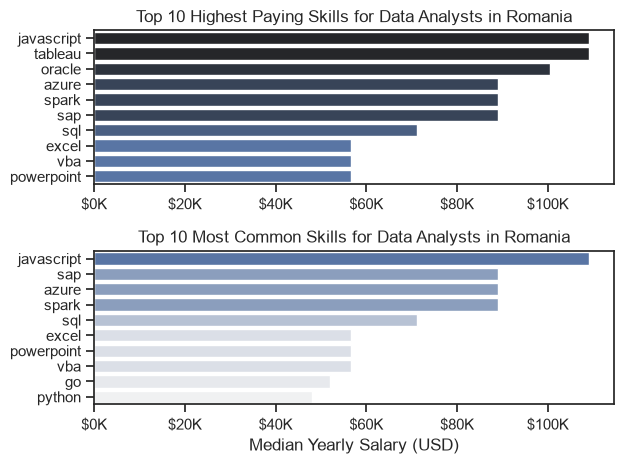

In [44]:
fig, ax = plt.subplots(2, 1)

sns.set_theme(style='ticks')

# Top 10 highest paying skills for Data Analysts in Romania
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, hue='median', ax=ax[0], palette='dark:b_r')
ax[0].legend().remove()
ax[0].set_title('Top 10 Highest Paying Skills for Data Analysts in Romania')
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

# Top 10 most common skills for Data Analysts in Romania
sns.barplot(data=df_DA_skills, x='median', y=df_DA_skills.index, hue='median', ax=ax[1], palette='light:b')
ax[1].legend().remove()
ax[1].set_title('Top 10 Most Common Skills for Data Analysts in Romania')
ax[1].set_xlabel('Median Yearly Salary (USD)')
ax[1].set_ylabel('')
ax[1].set_xlim(ax[0].get_xlim())
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.tight_layout()
plt.show()
